# 02 — Data cleaning

**Objective.** Apply and inspect cleaning, validation, verdict normalisation and de-duplication.

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.figsize'] = (9, 4)
from ml.config import PROCESSED_DATASET, ARTIFACTS_DIR, METADATA_DIR, RAW_DIR
df = pd.read_csv(PROCESSED_DATASET)
print(f'{len(df):,} processed fact-checks')

4,137 processed fact-checks


## Text normalisation
The same `clean_text` runs at training and inference time (no training/serving skew).

In [2]:
from ml.preprocessing.text_cleaning import clean_text, model_text, WORD_TOKEN_PATTERN
import re
for s in ['<p>Rs 500 notes&nbsp;banned!!</p>', 'यह\u200b वीडियो पुराना है', 'Check https://x.com/abc NOW']:
    print(repr(s), '->', repr(clean_text(s)), '| model:', repr(model_text(s)))
print(re.findall(r'(?u)\b\w\w+\b', 'प्रदर्शनकारियों पर'), 'vs', re.findall(WORD_TOKEN_PATTERN, 'प्रदर्शनकारियों पर'))

'<p>Rs 500 notes&nbsp;banned!!</p>' -> '₹500 notes banned!!' | model: '₹500 notes banned!!'
'यह\u200b वीडियो पुराना है' -> 'यह वीडियो पुराना है' | model: 'यह वीडियो पुराना है'
'Check https://x.com/abc NOW' -> 'Check https://x.com/abc NOW' | model: 'check urltoken now'
['रदर', 'शनक', 'पर'] vs ['प्रदर्शनकारियों', 'पर']


The last line shows a real bug we fixed: Python's `\w` does not match Indic vowel signs, so the default scikit-learn token pattern splits Hindi words into fragments.

## Verdict normalisation
Ordered regex rules; unmatched records stay unlabelled.

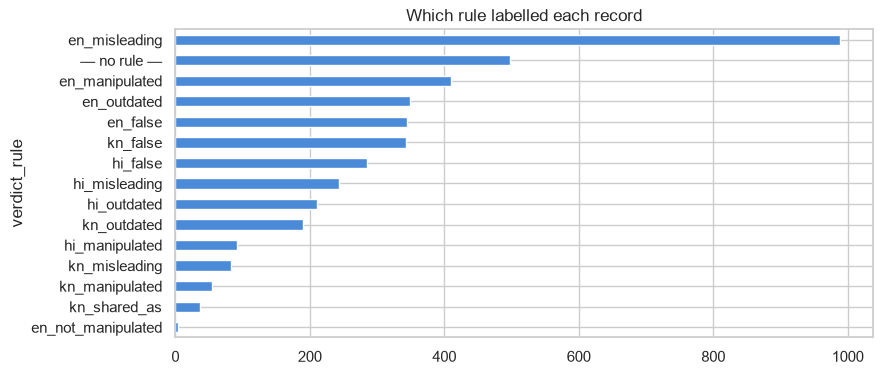

In [3]:
ax = df['verdict_rule'].fillna('— no rule —').value_counts().head(15).plot.barh(color='#4a8ad6'); ax.invert_yaxis(); ax.set_title('Which rule labelled each record'); plt.show()

In [4]:
df.sample(12, random_state=3)[['verdict','verdict_rule','fact_check_title']]

,verdict,verdict_rule,fact_check_title
3971,FALSE,kn_false,"ಈ ಫೋಟೋದಲ್ಲಿರುವ ಹುಡುಗನನ್ನು ಕಳ್ಳತನಕ್ಕಾಗಿ ಅಲ್ಲ, ಕ..."
160,FALSE,en_manipulated,This video of Ravish Kumar criticising AAP and...
2201,MISLEADING,en_misleading,Bihar Drowning Incident Video Shared as Hindu ...
3882,NaN,NaN,"ಮನಮೋಹನ್ ಸಿಂಗ್ ಆಡಳಿತದಲ್ಲಿ ಮಾತ್ರವಲ್ಲ, ಮೋದಿ ಸರ್ಕಾ..."
3540,FALSE,hi_false,दैनिक जागरण ने पाकिस्तान पर सर्जिकल स्ट्राइक क...
2409,FALSE,en_manipulated,Video showing BJP's Kapil Mishra making commun...
2848,FALSE,hi_false,RG कर रेप और हत्या मामले में तानिया यास्मीन ना...
1732,NaN,NaN,The RBI has not directed banks to stop disburs...
1061,OUTDATED,en_outdated,Old video of RJD leader Sima Kushwaha crying o...
2811,FALSE,hi_false,ताबूत में सीताराम येचुरी का शव देख राईटविंग इन...


## De-duplication and near-duplicate groups

In [5]:
rep = json.loads((METADATA_DIR / 'dataset_report.json').read_text(encoding='utf-8'))
{k: rep[k] for k in ('raw_rows','invalid_rows','duplicate_urls','duplicate_claim_texts','near_duplicate_rows','near_duplicate_groups','verdicts_changed_by_renormalisation','final_rows')}

{'raw_rows': 4138,
 'invalid_rows': 0,
 'duplicate_urls': 0,
 'duplicate_claim_texts': 1,
 'near_duplicate_rows': 18,
 'near_duplicate_groups': 9,
 'verdicts_changed_by_renormalisation': 552,
 'final_rows': 4137}

In [6]:
sizes = df.groupby('group_id').size(); g = sizes[sizes > 1].index[:3]
df[df.group_id.isin(g)].sort_values('group_id')[['group_id','publisher','language','claim_text']]

,group_id,publisher,language,claim_text
1672,1010,Alt News,hi,ईरान और इज़राइल के बीच चल रहे हालिया संघर्ष का...
1665,1010,Alt News,hi,ईरान और इज़राइल के बीच चल रहे हालिया संघर्ष से...
1802,1027,Alt News,hi,'जासूसी' के आरोप में गिरफ़्तार ज्योति मल्होत्र...
1801,1027,Alt News,hi,'जासूसी' के आरोप में गिरफ़्तार ज्योति मल्होत्र...
23,1579,Factly,en,Video of protesters in France attacking securi...
1206,1579,Factly,en,Video of protesters in Nepal attacking securit...


## Observations
* Exact duplicates are rare (sources rarely re-publish), but near-duplicate groups exist and are kept together during splitting.
* Verdict labels have measurable noise (see `data/metadata/verdict_audit.md`: ~8% clear errors).

**Conclusion.** The processed dataset is clean, attributable and honest about what it does not know.